# 현재 5개 task — 한 task의 실패가 전체 점수에 가려지지 않도록

**각 모델에서 task별 F1 최저 30% 이상 · 5개 F1의 중앙값 60% 이상 · 모든 task와 전체 정상 오탐률 5% 미만.**

이 기준은 통과했다. 그러나 **전체 합산 F1이 모두 오른 것은 아니다. IF는 이전 균형 버전 복원, K-means는 유지, LOF는 취약 task 회복과 다른 task 하락의 교환**이다. 아래에서 동일 5개 task끼리 비교한다.

In [1]:
from pathlib import Path
import json,numpy as np,pandas as pd
from IPython.display import display,Image,Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents]if(p/'reports/shared_model_v5/release/summary.json').exists())
LOG=ROOT/'reports/shared_model_v5/release'
read=lambda p:json.loads(p.read_text(encoding='utf8'))
s=read(LOG/'summary.json');sel=read(LOG/'selection.json');h=read(LOG/'handoff/manifest.json')
alg=['if','kmeans','lof'];tasks=s['protocol']['active_tasks']
def metrics(rows):
    return (pd.DataFrame(rows).set_index('method')[['accuracy','precision','recall','f1','normal_false_positive_rate']]*100).round(4)

## 1. 평가 범위와 판정 단위

컬럼 관계·Hard 혼합은 현재 평가에서 제외했다. 원본은 `reports/retired_tasks_20261018`에서 복구 가능하다. **남은 5개 task의 CSV·정답·난이도는 변경하지 않았다.** 63개 활성/보관 task 파일의 해시를 확인했다. 기존 하드 룰 전수 검증은 동일 파일에 한해 승계했으며 새로 실행했다고 주장하지 않는다.

각 task 이상 사례 5,000개 + 정상 대조군 5,000개. 평가는 **1,927,972개 1분 판정**, 정상 1,596,121 / 이상 331,851이다. 한 사례는 여러 분이므로 사례 수와 판정 수가 다르다. STATUS는 S. ADBench 데이터·모델·결과는 이번에 바꾸지 않았다.

In [2]:
display(s['protocol']);display(metrics(s['pooled']))
display(pd.DataFrame(s['acceptance']).T)
assert s['all_targets_met']

{'decisions': 1927972,
 'normal': 1596121,
 'anomaly': 331851,
 'active_tasks': ['individual_delay',
  'group_delay',
  'time_burst',
  'input_stop',
  'gradual_degradation'],
 'retained_test_data_modified': False,
 'point_adjustment': False,
 'single_estimator_each': True,
 'adapter_experts': False,
 'adoption_uses_reused_research_benchmark': True,
 'external_blind_test': False}

,accuracy,precision,recall,f1,normal_false_positive_rate
method,,,,,
if,88.7135,76.8729,49.2432,60.0314,3.0802
kmeans,92.7763,88.8326,66.3765,75.9800,1.7349
lof,90.9211,83.6258,58.7589,69.0209,2.3920


,minimum_task_F1,median_task_F1,maximum_task_normal_FPR,minimum_F1_met,median_F1_met,all_task_FPR_below_5pct,all_met,pooled_FPR_below_5pct
if,0.398935,0.64303,0.049971,True,True,True,True,True
kmeans,0.62634,0.720717,0.028531,True,True,True,True,True
lof,0.503721,0.704461,0.048155,True,True,True,True,True


## 2. task별 F1과 오탐

첫 그래프는 탐지 성능, 두 번째는 정상 데이터를 잘못 경보한 비율이다. 오탐은 FP/(TN+FP). **중앙값은 모델 하나의 task F1 5개를 정렬한 가운데 값**이며 전체 F1이나 3개 모델의 중앙값이 아니다. IF 점진적 악화 오탐 **4.9971%**는 수치상 통과이나 운영 여유가 거의 없다.

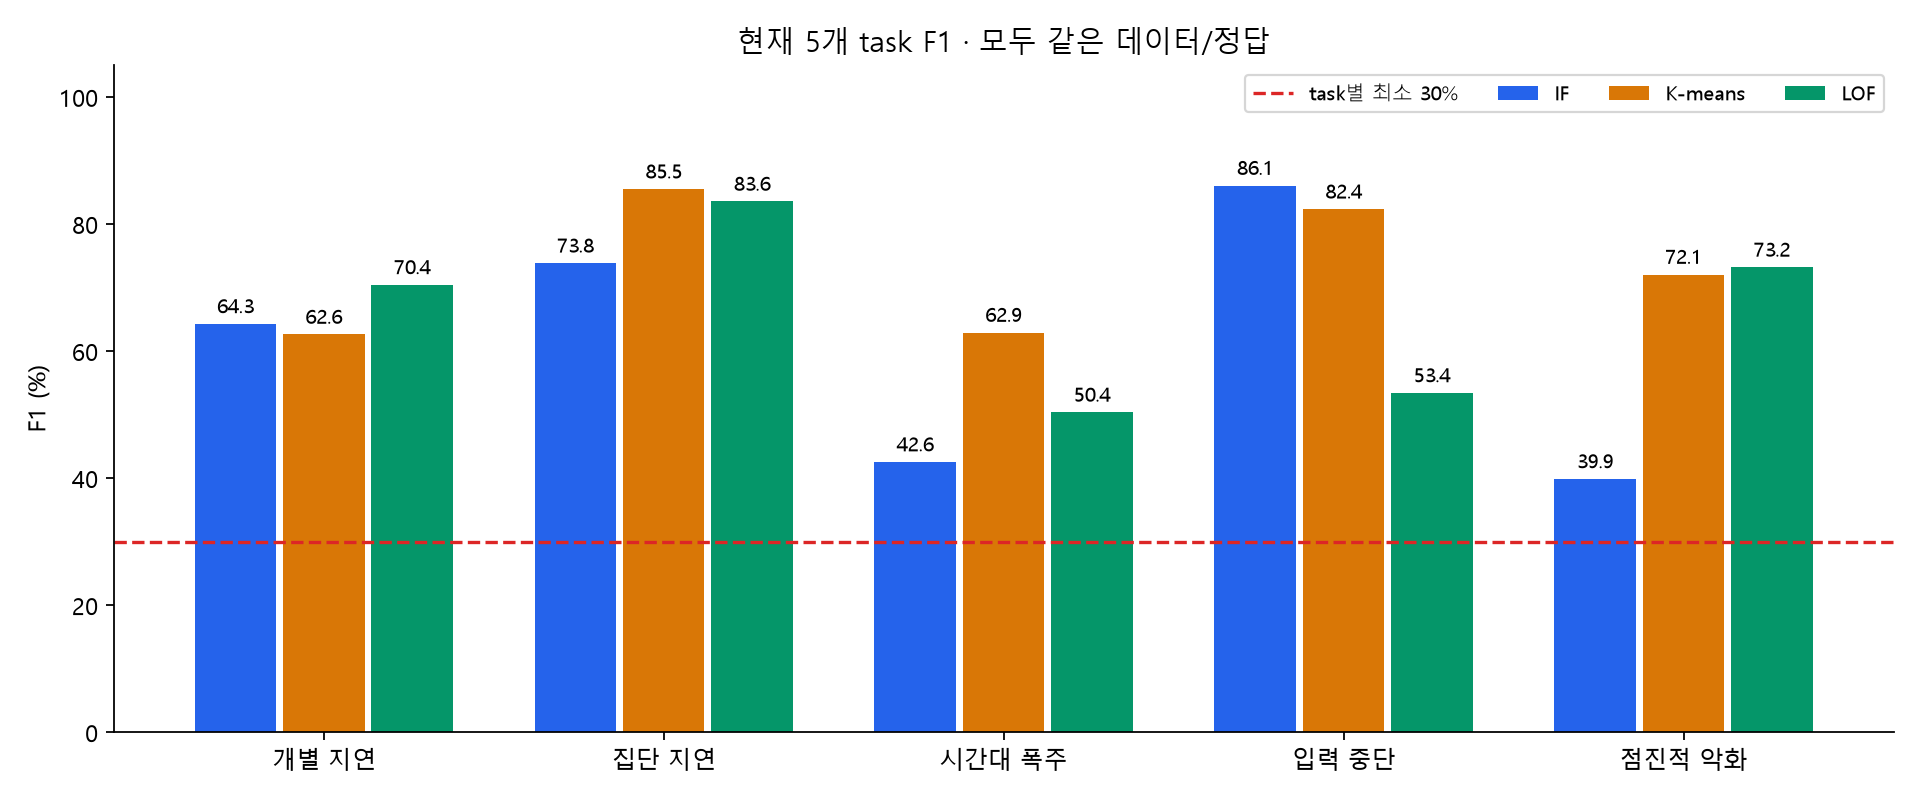

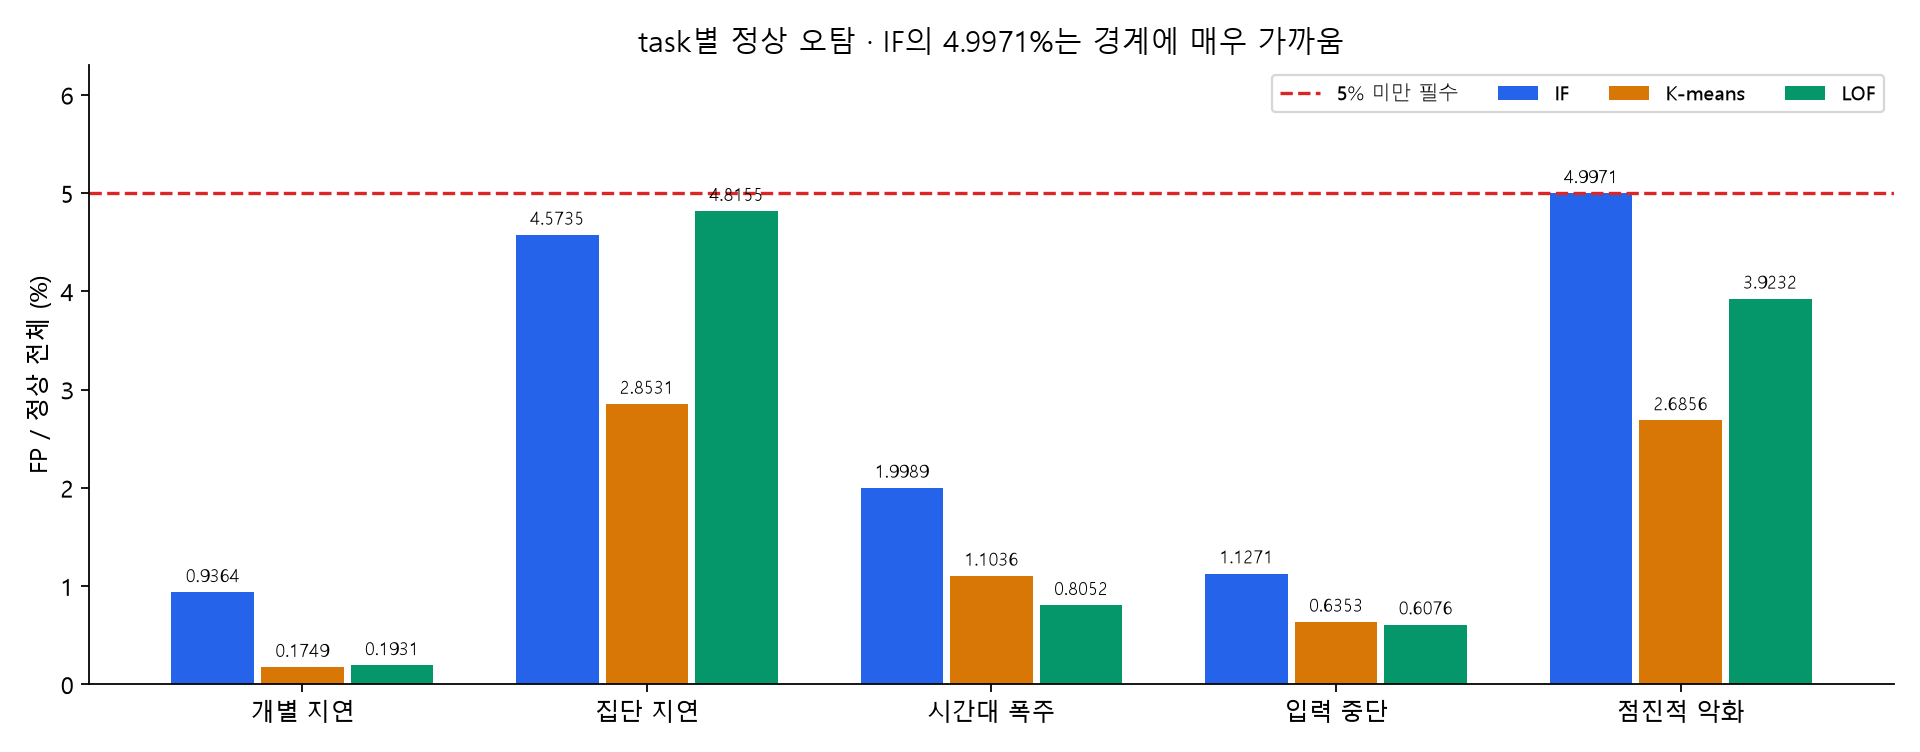

,task,method,tp,fp,fn,tn,precision,recall,f1,normal_false_positive_rate
0,individual_delay,if,2657,514,2436,54377,0.837906,0.521696,0.643030,0.009364
1,individual_delay,kmeans,2366,96,2727,54795,0.961007,0.464559,0.626340,0.001749
2,individual_delay,lof,2827,106,2266,54785,0.963860,0.555076,0.704461,0.001931
3,group_delay,if,40527,14119,14589,294595,0.741628,0.735304,0.738452,0.045735
4,group_delay,kmeans,47743,8808,7373,299906,0.844247,0.866228,0.855096,0.028531
5,group_delay,lof,50236,14866,4880,293848,0.771651,0.911459,0.835748,0.048155
6,time_burst,if,13190,7140,28473,350053,0.648795,0.316588,0.425532,0.019989
7,time_burst,kmeans,20942,3942,20721,353251,0.841585,0.502652,0.629390,0.011036
8,time_burst,lof,14994,2876,26669,354317,0.839060,0.359888,0.503721,0.008052
9,input_stop,if,64029,4762,15960,417737,0.930776,0.800473,0.860721,0.011271


In [3]:
display(Image(filename=str(LOG/'figures/task_f1.png')))
display(Image(filename=str(LOG/'figures/task_fpr.png')))
rows=[]
for d in s['datasets']:
    for r in d['metrics']:rows.append({'task':d['dataset'],**r})
table=pd.DataFrame(rows)
display(table[['task','method','tp','fp','fn','tn','precision','recall','f1','normal_false_positive_rate']].round(6))

## 3. 같은 5개 task끼리 전후 비교

제외한 task 때문에 합산 점수가 달라지는 효과를 개선으로 포장하지 않는다. 직전 `shared_model_v4_final`에서도 같은 5개만 뽑아 비교한다. **IF와 LOF는 최약 task를 회복했지만 전체 합산 F1·일부 다른 task는 하락했다. K-means는 같은 모델이므로 task별 성능이 그대로다.**

In [4]:
old=read(ROOT/'reports/shared_model_v4_final/summary.json');old_by={d['dataset']:d for d in old['datasets']}
comparison=[];pooled=[]
for i,a in enumerate(alg):
    before=[old_by[t]['metrics'][i]for t in tasks];now=[d['metrics'][i]for d in s['datasets']]
    for t,b,r in zip(tasks,before,now):comparison.append({'task':t,'model':a,'before F1 %':b['f1']*100,'now F1 %':r['f1']*100,'change pp':(r['f1']-b['f1'])*100})
    tp=sum(r['tp']for r in before);fp=sum(r['fp']for r in before);fn=sum(r['fn']for r in before)
    pooled.append({'model':a,'before pooled F1 %':200*tp/(2*tp+fp+fn),'now pooled F1 %':s['pooled'][i]['f1']*100,'before minimum F1 %':min(r['f1']for r in before)*100,'now minimum F1 %':s['acceptance'][a]['minimum_task_F1']*100})
display(pd.DataFrame(pooled).round(2));display(pd.DataFrame(comparison).round(2))

,model,before pooled F1 %,now pooled F1 %,before minimum F1 %,now minimum F1 %
0,if,68.76,60.03,0.00,39.89
1,kmeans,75.98,75.98,62.63,62.63
2,lof,73.69,69.02,3.16,50.37


,task,model,before F1 %,now F1 %,change pp
0,individual_delay,if,0.00,64.30,64.30
1,group_delay,if,82.27,73.85,-8.42
2,time_burst,if,34.00,42.55,8.56
3,input_stop,if,73.07,86.07,13.00
4,gradual_degradation,if,69.35,39.89,-29.46
5,individual_delay,kmeans,62.63,62.63,0.00
6,group_delay,kmeans,85.51,85.51,0.00
7,time_burst,kmeans,62.94,62.94,0.00
8,input_stop,kmeans,82.35,82.35,0.00
9,gradual_degradation,kmeans,72.07,72.07,0.00


## 4. Isolation Forest — 개별 지연 누락을 복구

직전 개별 지연 이상 5,093개 분에서 TP=0이었다. 이전 정상 학습 IF를 복원해 **TP 2,657 / F1 64.30%**로 회복했다. 입력 중단 F1 **86.07%**가 현재 세 모델 중 높다. 반면 점진적 악화 F1은 **39.89%**, 해당 task 오탐은 경계에 가까워 약점이다.

**새 재학습 성과가 아니라 이전 균형 버전 복원이다.** 26개 피처, 500 trees, max_samples=32, max_features=0.5. 정상 공분산 변환과 고정 회전, 관측 상태별 정상 점수 보정 사용.

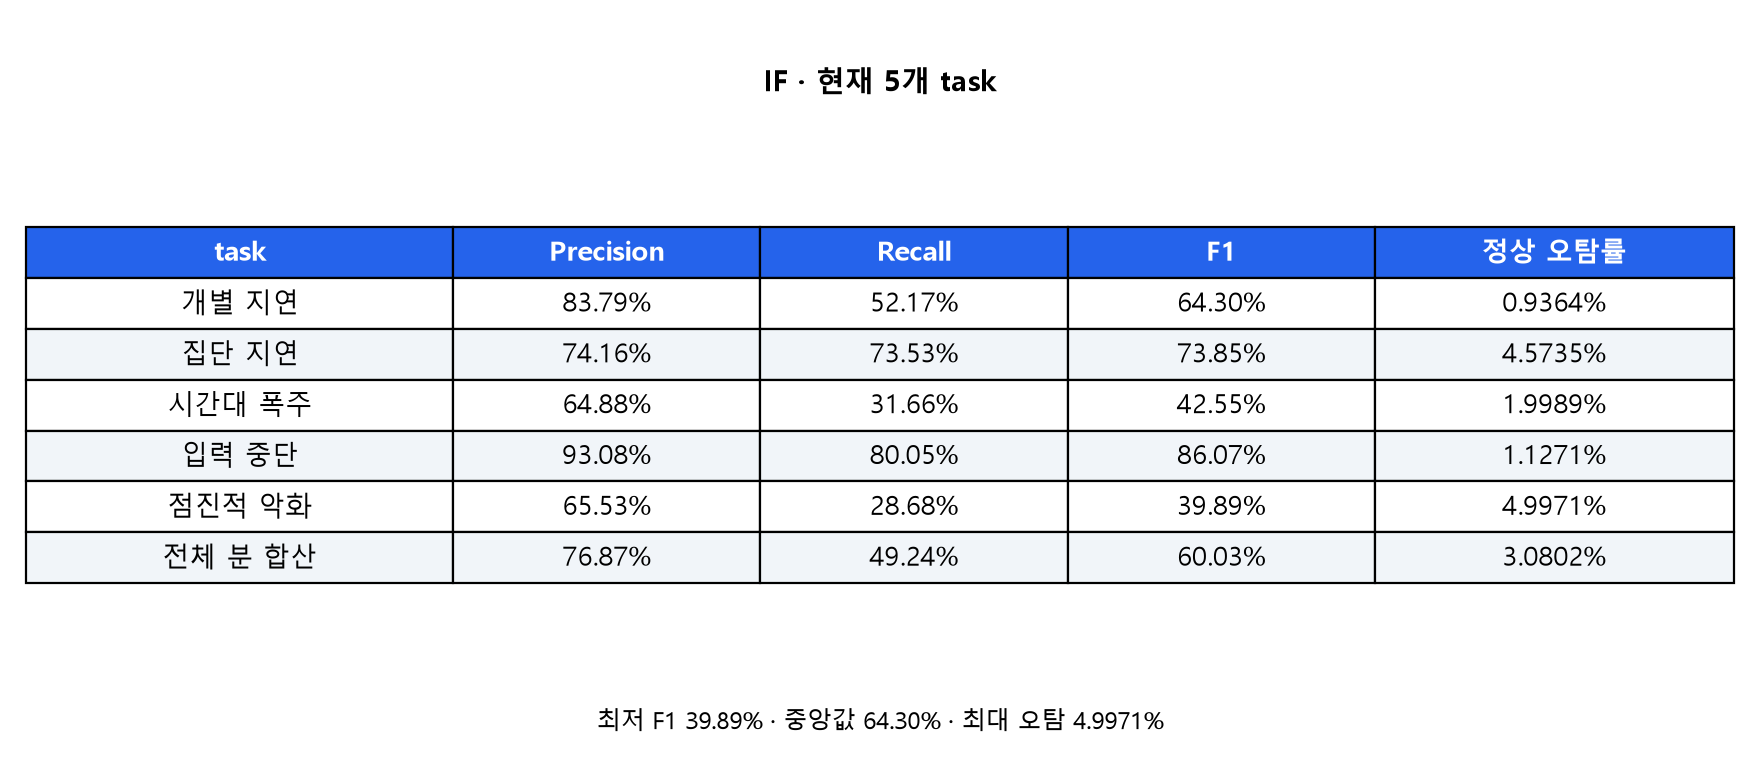

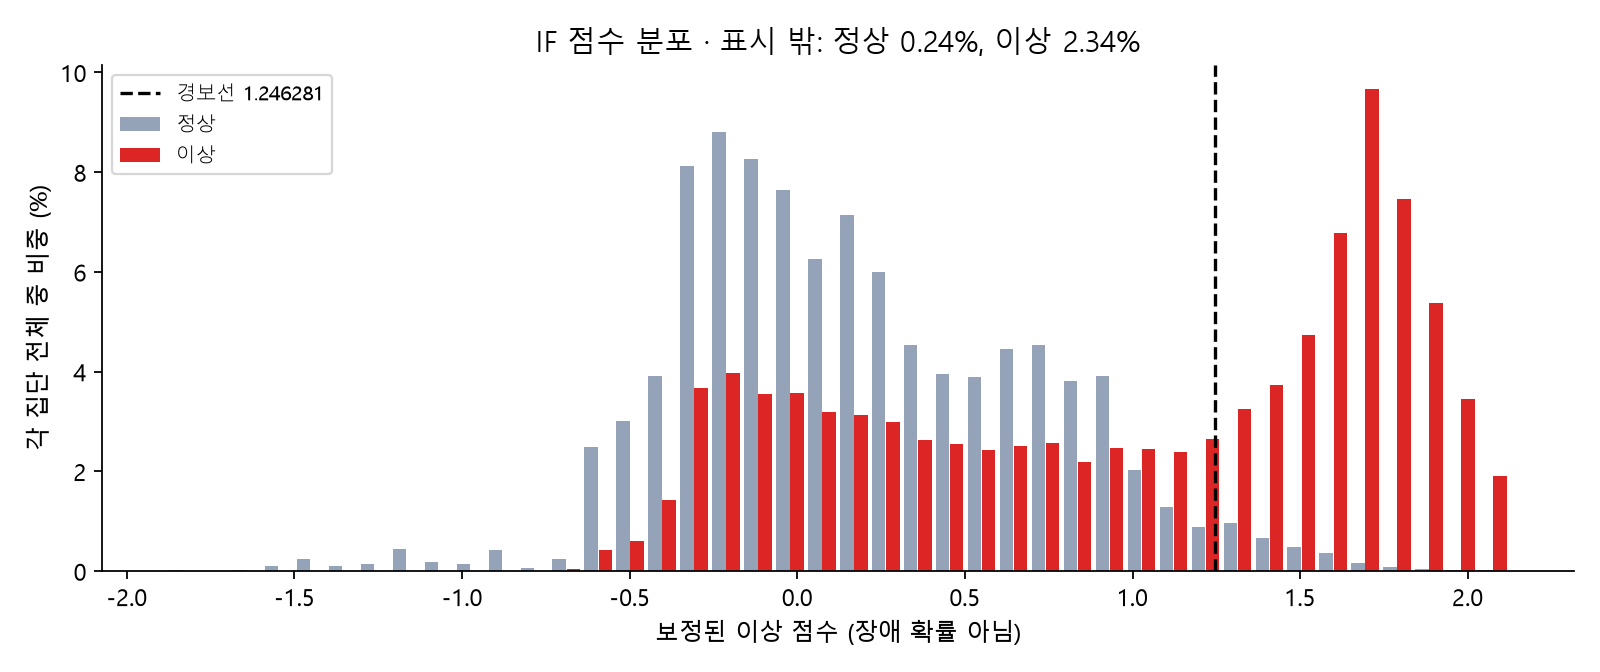

In [5]:
display(Image(filename=str(LOG/'figures/if_performance.png')))
display(Image(filename=str(LOG/'figures/if_threshold.png')))

## 5. MiniBatch K-means — 현재 가장 안정적인 범용 후보

기존 모델을 그대로 유지했다. 모든 task F1 **62.63% 이상**, 시간대 폭주 **62.94%**, 최대 task 오탐 **2.8531%**. 개별 지연 Recall은 46.46%라 높은 Precision만 보고 모두 잘 찾는다고 해석하면 안 된다.

19개 피처, 8개 군집. 각 정상 중심까지 거리/정상 P95 반경의 최솟값을 점수로 쓴다. 정상 공분산 whitening과 관측 상태별 CDF 보정을 적용한다. Adapter 전문가 모델은 아니다.

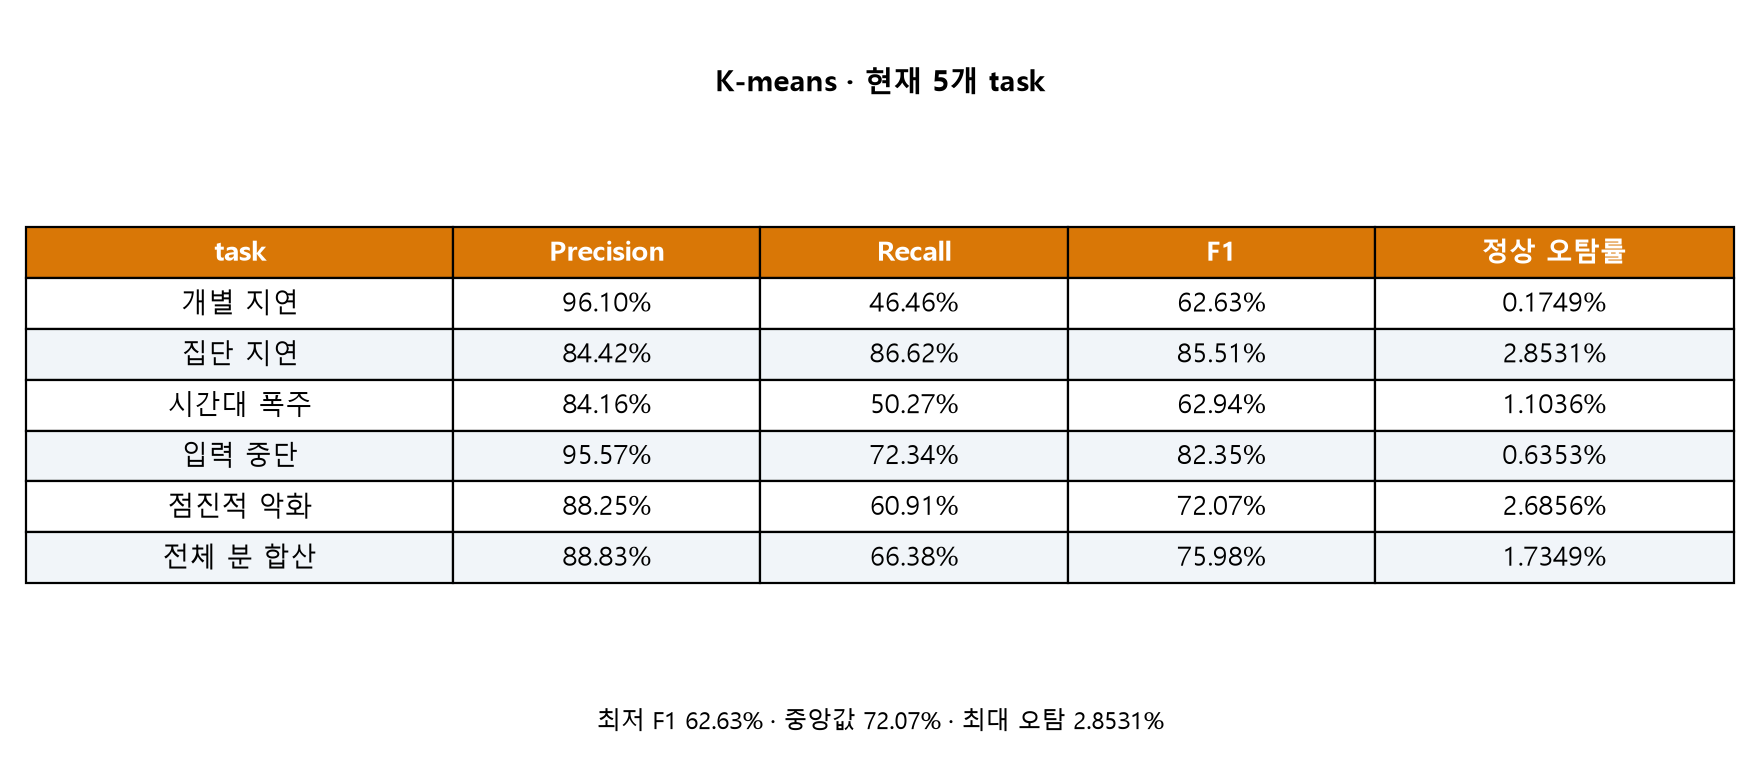

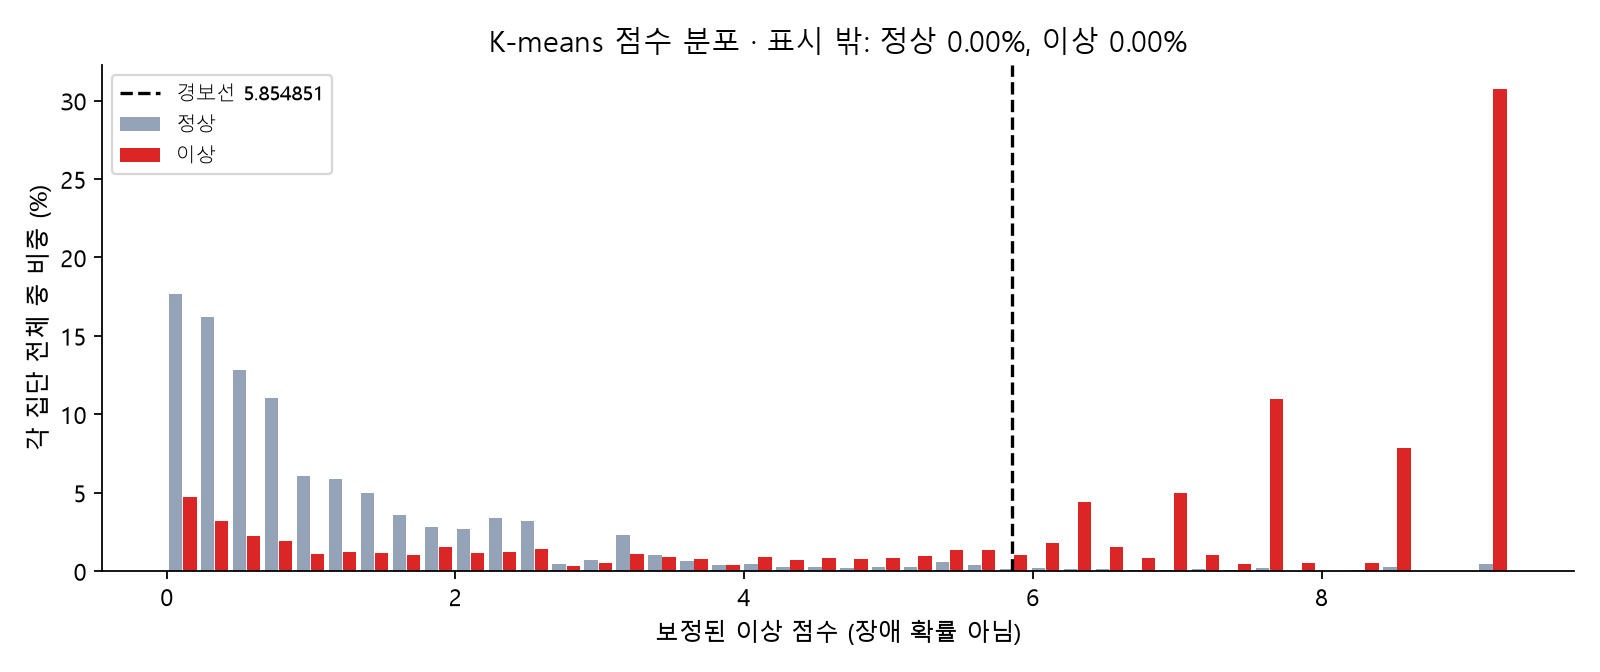

In [6]:
display(Image(filename=str(LOG/'figures/kmeans_performance.png')))
display(Image(filename=str(LOG/'figures/kmeans_threshold.png')))

## 6. LOF — 폭주 취약성을 회복하되 중단 탐지는 하락

같은 정상 후보로 이미 학습한 표현 후보를 새 5-task 기준으로 재선정했다. **asinh → linear+whitening, 이웃 800 → 200, 참조점 최대 4096 → 2048**, 정상 점수 CDF 보정과 정상 calibration P99.5를 채택했다. 현재 LOF는 28개 피처를 사용한다.

직전 대비 개별 지연 **40.39 → 70.45%**, 시간대 폭주 **3.16 → 50.37%**. 반면 입력 중단 **83.41 → 53.43%**, 집단 지연도 소폭 하락했다. 점진적 악화는 **73.20%**. LOF가 모든 task에서 더 좋아졌다는 결론은 아니다.

P99.25의 첫 후보는 집단 지연 오탐 5.58%로 탈락했다. 정상 자료에서 계산한 P99.5/P99.75도 비교했으며 탈락 기록은 `adoption_candidates.json`에 남겼다. **반복 사용한 연구 벤치마크의 정답을 채택 판단에 활용했으므로 블라인드 테스트가 아니다.**

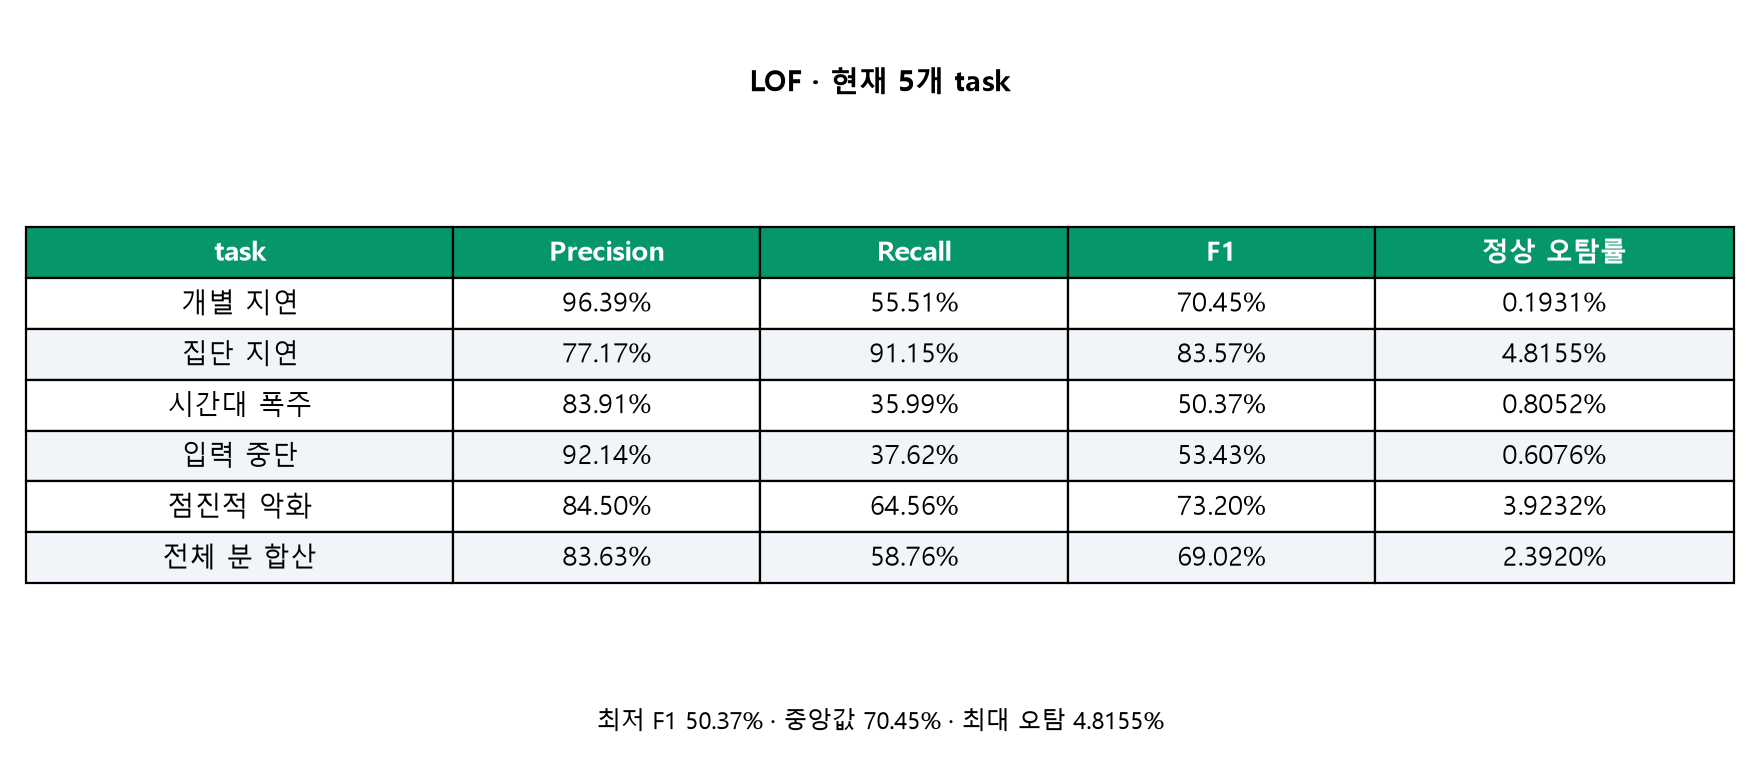

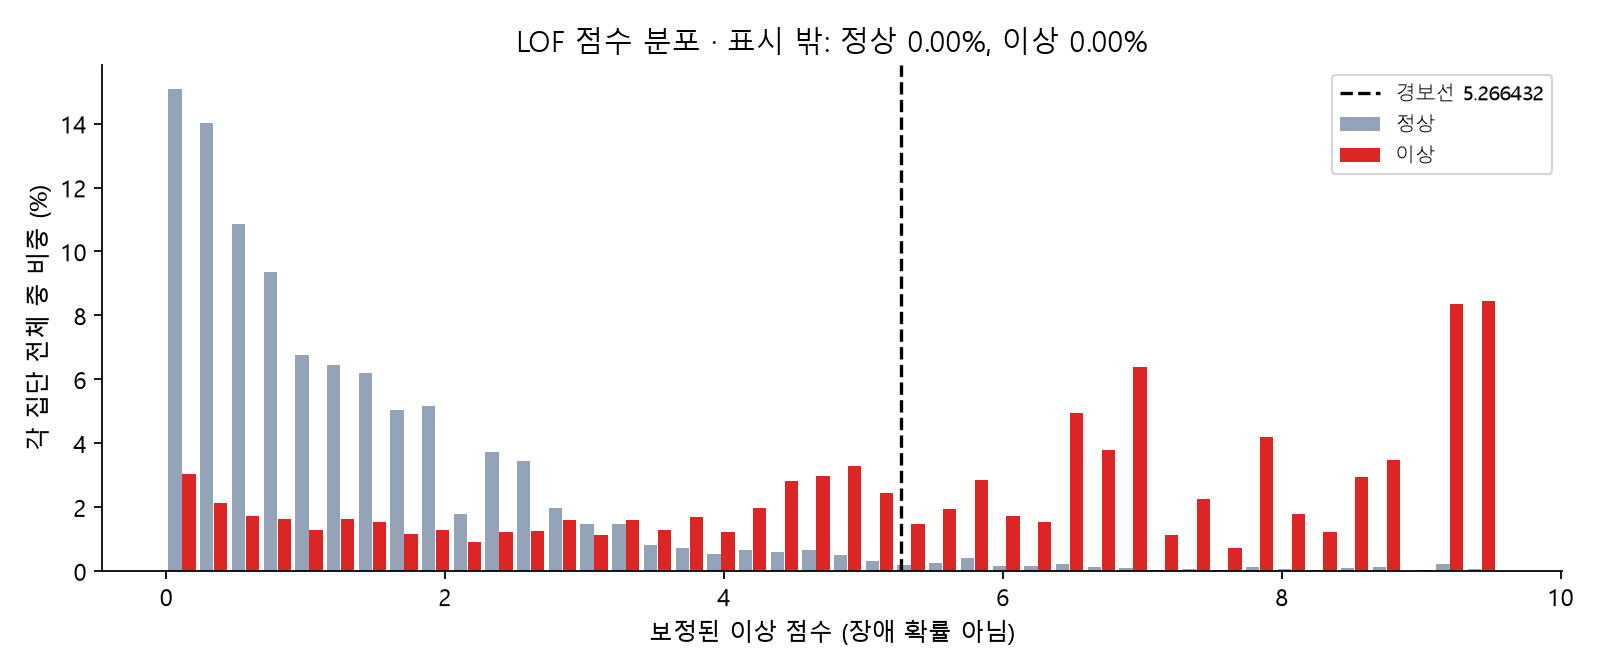

,q,threshold,minimum_task_F1,median_task_F1,maximum_task_normal_FPR,minimum_F1_met,median_F1_met,all_task_FPR_below_5pct,all_met
0,0.9925,4.910083,0.530711,0.708307,0.055835,True,True,False,False
1,0.9950,5.266432,0.503721,0.704461,0.048155,True,True,True,True
2,0.9975,5.832996,0.462959,0.641235,0.034433,True,True,True,True


In [7]:
display(Image(filename=str(LOG/'figures/lof_performance.png')))
display(Image(filename=str(LOG/'figures/lof_threshold.png')))
display(pd.DataFrame(read(ROOT/'reports/shared_model_v5/adoption_candidates.json')['candidates']).drop(columns=['tasks']))

## 7. 피처·학습·경보선은 무엇인가

- 실행 종류는 **adapterType + processId**. 별도의 업무 의미 컬럼은 아니다. 처리 건수는 **totalCount**이며 분당 요청 수와 다르다.
- 소요시간은 **endTime−startTime**. 같은 실행 종류·처리 건수의 과거 정상 후보 범위 대비 이탈을 `current_source_upper/lower` 등으로 전달한다. Adapter별 통계 피처는 별도 전문가 모델과 다르다.
- 최근 요청 수 증가·0건 지속, 완료 관측 대비 지연·추세를 과거 방향으로 계산한다. K-means·LOF의 rank 피처는 초기 완료 관측 최대 6개를 참조한다. 초기 6개가 정상이라는 보장은 없다. IF는 복원한 current 표현을 사용한다.
- 정상 후보 19,793개 분으로 추정기를 학습했고 별도 정상 17,925개 분으로 점수를 보정했다. LOF는 중복 제거 후 2,048개만 참조점으로 사용한다. S는 처리 성공이지 성능 정상 인증이 아니다.
- **score > threshold**일 때 경보한다. 점수는 확률이 아니며 모델마다 단위가 다르다. 정상 분위수가 운영 오탐을 보장하지 않는다.

In [8]:
for r in h['models']:
    display(Markdown('### '+r['algorithm']))
    display(pd.Series({'features':len(r['columns']),'fit rows':r['fit_rows'],'threshold':r['threshold'],'calibration':r['calibration_mode']+' / '+r['calibration_kind'],'estimator':r['actual_estimator_parameters']}).to_frame('실제 설정'))
    display(pd.Series(r['columns'],name='입력 피처').to_frame())

### if

,실제 설정
features,26
fit rows,19793
threshold,1.246281
calibration,availability / robust
estimator,"{'bootstrap': False, 'contamination': 'auto', ..."


,입력 피처
0,current_arrival_excess
1,current_prefix_burst
2,gap_expected_prefix
3,gap_expected_recent
4,empty_expected_rate
5,current_source_delay
6,current_source_upper
7,current_source_lower
8,current_prefix_delay
9,current_recent_delay


### kmeans

,실제 설정
features,19
fit rows,19793
threshold,5.854851
calibration,availability / cdf
estimator,"{'batch_size': 2048, 'compute_labels': True, '..."


,입력 피처
0,current_arrival_excess
1,current_prefix_burst
2,gap_expected_prefix
3,gap_expected_recent
4,empty_expected_rate
5,current_source_upper
6,current_source_lower
7,rank_upper_run
8,rank_lower_run
9,rank_upper_memory


### lof

,실제 설정
features,28
fit rows,2048
threshold,5.266432
calibration,availability / cdf
estimator,"{'algorithm': 'auto', 'contamination': 'auto',..."


,입력 피처
0,current_arrival_excess
1,current_prefix_burst
2,gap_expected_prefix
3,gap_expected_recent
4,empty_expected_rate
5,current_source_upper
6,current_source_lower
7,adapter_max_duration_z
8,adapter_p95_upper_tail
9,adapter_count_p95_z


## 8. 검증과 서비스 전달

독립 confusion matrix 재계산, 71개 테스트, 원시 Process 입력 경로·저장/로드 점수 일치·미지 Adapter fallback·미래 로그가 과거 점수를 바꾸지 않는지 확인했다. 실행된 결과는 아래에서 읽는다.

`reports/shared_model_v5/release/handoff/{if,kmeans,lof}_shared.joblib`가 현재 전달용 모델이다. 함께 `code/` 모듈 트리가 필요하다. **worker는 빈 1분 시간창, 이전 이력, 지연 도착을 처리해야 하며 실시간 상태 관리와 운영 배포가 완료된 것은 아니다.** 현재 테스트를 여러 번 확인한 연구 결과이므로 실제 운영 로그로 별도 검증해야 한다.

In [9]:
audit=read(LOG/'audit.json');display({k:v for k,v in audit.items()if k!='raw_serving_checks'})
display(pd.DataFrame([{'model':r['algorithm'],'file':r['file'],'bytes':r['bytes'],'raw Process':r['raw_Process_predict'],'prefix causal':r['prefix_causal']}for r in h['models']]))

{'checks_passed': True,
 'all_targets_met': True,
 'unit_tests_run': 71,
 'unit_tests_passed': True,
 'independent_confusion_counts': True,
 'remaining_data_labels_unchanged': True,
 'ADBench_unchanged': True,
 'model_sha256': 'd9331b441610cd0b6951e1d429fd60ab08be7ebc21ccdb02d503fae271f06237',
 'summary_sha256': 'fb160366ef36bb2c395213f9faef8331d0b34092c26b278e84fff9f9c1fcdab5',
 'external_blind_test': False}

,model,file,bytes,raw Process,prefix causal
0,if,if_shared.joblib,639109,True,True
1,kmeans,kmeans_shared.joblib,343338,True,True
2,lof,lof_shared.joblib,1900059,True,True
